# AV-Ready-Saudi — results notebook

Every figure and table in the **Results** section of the research paper comes from this notebook (Dr. Omar's rule:
*"all figures, tables, charts are derived from your own Notebook"*). Figures 1–2 of the paper (architecture and
relations) are diagrams, redrawn by hand in PowerPoint; they are not produced here.

**Input** — the outputs of one pipeline run (`run_pipeline_mac.sh` / `run_pipeline.ps1`):

| file | what it is |
|---|---|
| `Data/gold_export/gold_av_readiness_region_month.csv` | the one Gold table, exported from SQL Server (780 rows) |
| `Data/gold_export/av_relative_risk.tsv` | the AV evidence table (`prep.av_relative_risk`) |
| `Data/model/av_evidence_glm.csv`, `av_evidence_holdout.csv` | GLM cross-check and hold-out from `python/04_av_evidence_models.py` |
| `Data/model/*.csv`, `model_summary.json` | outputs of `python/05_readiness_model.py`, used only for the consistency check at the end |

**Method** — the readiness score, clustering, supervised test and sensitivity are recomputed here with the *same
functions* as `python/05_readiness_model.py` (imported, not copied), so the notebook and the pipeline cannot drift apart.
The last section checks that the notebook reproduces the pipeline run exactly.

**Output** — `docs/paper/figures/*.png` (300 dpi, IEEE column widths: 3.5 in single, 7.16 in double) and
`docs/paper/tables/*.csv` (the numbers to type into the paper's tables).

**Run** — open in VS Code (Jupyter extension) or Jupyter, choose the project's `.venv` kernel, *Run All*. About 2–4
minutes; the dew-point sensitivity re-reads the hourly weather from `Data/landing/` (skipped, with a note, if absent).

In [1]:
import importlib.util
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

# repository root = the folder that holds python/05_readiness_model.py
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "python" / "05_readiness_model.py").exists())
spec = importlib.util.spec_from_file_location("readiness", ROOT / "python" / "05_readiness_model.py")
rm = importlib.util.module_from_spec(spec)
spec.loader.exec_module(rm)          # the pipeline's own functions: pillars, score, clustering, supervised, sensitivity

FIG = ROOT / "docs" / "paper" / "figures"
TAB = ROOT / "docs" / "paper" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

# IEEE figure style: 8 pt text, column widths in inches, PNG at 300 dpi
SINGLE, DOUBLE = 3.5, 7.16
plt.rcParams.update({"font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8, "xtick.labelsize": 7.5,
                     "ytick.labelsize": 7.5, "legend.fontsize": 7.5, "font.family": "DejaVu Sans",
                     "axes.edgecolor": rm.INK2, "axes.labelcolor": rm.INK, "xtick.color": rm.INK2,
                     "ytick.color": rm.INK2, "savefig.dpi": 300, "figure.dpi": 110})
BLUE, ORANGE, AQUA, YELLOW = rm.BLUE, rm.ORANGE, rm.AQUA, "#f2a600"
COND_COLOR = {"dust": ORANGE, "haze_dry": YELLOW, "fog_moist": AQUA, "rain": BLUE}
COND_LABEL = {"normal": "normal", "dust": "dust / sand", "haze_dry": "dry haze", "fog_moist": "moist fog / mist",
              "rain": "rain", "obscured": "fog or haze (any)", "hot40": "hours >= 40 °C"}


def save(fig, name):
    p = FIG / f"{name}.png"
    fig.savefig(p, dpi=300, bbox_inches="tight", facecolor="white")
    print("saved", p.relative_to(ROOT))


def table(df, name, nd=3):
    p = TAB / f"{name}.csv"
    df.round(nd).to_csv(p, index=False)
    print("saved", p.relative_to(ROOT))
    return df.round(nd)


def style(ax, grid="y"):
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    if grid:
        ax.grid(axis=grid, color=rm.GRID, lw=0.6)
        ax.set_axisbelow(True)


print("repository:", ROOT)

repository: /home/claude/repo


## 1. Data: the Gold table

In [2]:
g, rr, src = rm.load_inputs()
names = g.drop_duplicates("region_code").set_index("region_code")["region_name_en"].to_dict()
complete = g[g["wx_complete"] == 1]
print("source:", src)
print(f"Gold rows: {len(g)}  ({g['region_code'].nunique()} regions x {g['month_start'].nunique()} months, "
      f"{g['month_start'].min():%b %Y} - {g['month_start'].max():%b %Y})")
print(f"complete weather months: {len(complete)}; months without usable weather: {len(g) - len(complete)}")
print("last month with weather:", g.loc[g["wx_hours_observed"] > 0, "month_start"].max().strftime("%b %Y"))

source: Gold export (SQL Server)
Gold rows: 780  (13 regions x 60 months, Jan 2021 - Dec 2025)
complete weather months: 715; months without usable weather: 65
last month with weather: Aug 2025


**Table — Gold columns by family.** Data columns that vary (numbers only; names, keys, lineage and load columns
excluded). These are the counts behind the "data share by Gold columns" in the review note.

In [3]:
families = {
    "weather (NOAA)": ["temp_mean_c", "temp_max_c", "wind_max_ms", "mean_dew_spread_c", "share_normal_hours",
                       "share_rain_hours", "share_fog_moist_hours", "share_haze_dry_hours", "share_dust_hours",
                       "share_haze_hours", "share_fog_hours", "share_low_vis_hours", "share_night_hours",
                       "share_hot40_hours", "share_hot45_hours", "days_observed", "dust_days", "dust_type_days",
                       "haze_dry_days", "fog_moist_days", "rain_days", "normal_days", "wx_hours_observed",
                       "wx_hours_in_month", "wx_coverage_pct"],
    "accidents (GASTAT)": ["acc_year_serious", "acc_year_deaths", "acc_year_injuries", "acc_year_serious_within_cities",
                           "acc_year_serious_outside_cities", "acc_share_outside_cities", "acc_serious_per_100k",
                           "acc_deaths_per_100k", "acc_injuries_per_100k"],
    "AV evidence (NHTSA, DMV)": ["av_uncovered_share", "av_uncovered_share_cons", "av_crash_multiplier",
                                 "env_readiness", "env_readiness_cons"],
    "roads (GASTAT)": ["road_km_per_1000_people", "road_km_per_km2", "intercity_road_km", "intercity_divided_share"],
    "region service (GASTAT)": ["response_within_s", "response_outside_s", "registered_vehicles_2025"],
    "traffic (GASTAT)": ["traffic_adt_per_point", "traffic_month_index"],
    "population (GASTAT)": ["population"],
}
rows = []
for fam, cols in families.items():
    varying = [c for c in cols if c in g.columns and g[c].nunique(dropna=True) > 1]
    rows.append((fam, len(varying)))
fam = pd.DataFrame(rows, columns=["family", "varying_numeric_columns"])
fam["share_pct"] = 100 * fam["varying_numeric_columns"] / fam["varying_numeric_columns"].sum()
table(fam, "table_gold_column_families", 1)

saved docs/paper/tables/table_gold_column_families.csv


,family,varying_numeric_columns,share_pct
0,weather (NOAA),25,51.0
1,accidents (GASTAT),9,18.4
2,"AV evidence (NHTSA, DMV)",5,10.2
3,roads (GASTAT),4,8.2
4,region service (GASTAT),3,6.1
5,traffic (GASTAT),2,4.1
6,population (GASTAT),1,2.0


## 2. EDA: how Saudi weather compares with the US AV evidence

In [4]:
w = g[g["wx_hours_observed"] > 0]
hrs = w["wx_hours_observed"]


def hour_share(col):
    return 100 * (w[col] * hrs).sum() / hrs.sum()


sa = {c: hour_share(f"share_{c}_hours") for c in ["normal", "dust", "haze_dry", "fog_moist", "rain", "hot40"]}
sa["obscured"] = sa["haze_dry"] + sa["fog_moist"]
us = rr[(rr["event_source"] == "nhtsa_crash") & (rr["factor"] == "weather")].set_index("condition_code")["exposure"]
us = 100 * us / us.sum()
cmp_rows = [("normal", sa["normal"], us.get("normal")), ("dust", sa["dust"], us.get("dust")),
            ("obscured", sa["obscured"], us.get("obscured_unspecified")), ("rain", sa["rain"], us.get("rain")),
            ("haze_dry", sa["haze_dry"], np.nan), ("fog_moist", sa["fog_moist"], np.nan), ("hot40", sa["hot40"], np.nan)]
cmp = pd.DataFrame(cmp_rows, columns=["condition", "saudi_pct_of_hours", "us_crash_exposure_pct_of_hours"])
cmp["condition"] = cmp["condition"].map(COND_LABEL)
print("Saudi: 13 stations, all hours with weather 2021 - Aug 2025.  US: station-hours behind the NHTSA crash")
print("relative risks (LAX, SFO, PHX, AUS in the crash state-months); the US side has no dry/moist split.")
table(cmp, "table_saudi_vs_us_conditions", 2)

Saudi: 13 stations, all hours with weather 2021 - Aug 2025.  US: station-hours behind the NHTSA crash
relative risks (LAX, SFO, PHX, AUS in the crash state-months); the US side has no dry/moist split.
saved docs/paper/tables/table_saudi_vs_us_conditions.csv


,condition,saudi_pct_of_hours,us_crash_exposure_pct_of_hours
0,normal,94.34,93.01
1,dust / sand,3.49,0.02
2,fog or haze (any),1.67,4.35
3,rain,0.51,2.62
4,dry haze,1.16,NaN
5,moist fog / mist,0.51,NaN
6,hours >= 40 °C,6.11,NaN


**Figure — non-normal weather by season (Saudi, share of hours).** Spring is the dust season; dry haze follows it.

saved docs/paper/figures/fig_saudi_conditions_by_season.png


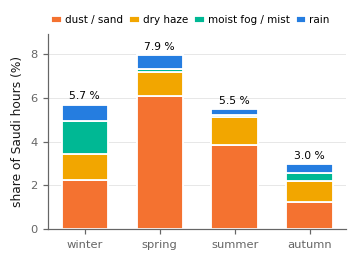

saved docs/paper/tables/table_saudi_conditions_by_season.csv


,season,dust,haze_dry,fog_moist,rain
0,winter,2.25,1.20,1.50,0.73
1,spring,6.07,1.13,0.13,0.61
2,summer,3.83,1.31,0.08,0.27
3,autumn,1.23,0.97,0.38,0.41


In [5]:
by_season = []
for s in rm.SEASONS:
    ws = w[w["season"] == s]
    h = ws["wx_hours_observed"]
    by_season.append({c: 100 * (ws[f"share_{c}_hours"] * h).sum() / h.sum() for c in COND_COLOR})
bs = pd.DataFrame(by_season, index=rm.SEASONS)
fig, ax = plt.subplots(figsize=(SINGLE, 2.3))
bottom = np.zeros(len(bs))
for c, col in COND_COLOR.items():
    ax.bar(bs.index, bs[c], bottom=bottom, color=col, edgecolor="white", linewidth=1.2, width=0.62, label=COND_LABEL[c])
    bottom += bs[c].to_numpy()
for i, v in enumerate(bottom):
    ax.text(i, v + 0.15, f"{v:.1f} %", ha="center", va="bottom", fontsize=7)
ax.set_ylabel("share of Saudi hours (%)")
ax.set_ylim(0, bottom.max() * 1.12)
ax.legend(ncol=4, frameon=False, loc="lower left", bbox_to_anchor=(-0.02, 1.0), handlelength=1.0,
          handletextpad=0.3, columnspacing=0.6, fontsize=6.8)
style(ax)
save(fig, "fig_saudi_conditions_by_season")
plt.show()
table(bs.reset_index().rename(columns={"index": "season"}), "table_saudi_conditions_by_season", 2)

**Figure — dust share by region and month of the year (Saudi, % of hours, 2021 – Aug 2025).**

saved docs/paper/figures/fig_dust_region_month.png


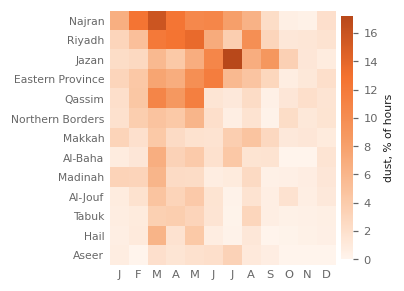

month of peak dust per region: {'Najran': 3, 'Riyadh': 5, 'Jazan': 7, 'Eastern Province': 6, 'Qassim': 5, 'Northern Borders': 5, 'Makkah': 8, 'Al-Baha': 3, 'Madinah': 3, 'Al-Jouf': 3, 'Tabuk': 4, 'Hail': 3, 'Aseer': 7}


In [6]:
dm = w.assign(dh=w["share_dust_hours"] * w["wx_hours_observed"])
dm = dm.groupby(["region_code", "month"]).agg(dh=("dh", "sum"), h=("wx_hours_observed", "sum"))
dm = (100 * dm["dh"] / dm["h"]).unstack("month")
order_dust = dm.mean(axis=1).sort_values(ascending=False).index
dm = dm.loc[order_dust]
fig, ax = plt.subplots(figsize=(2.85, 3.0))
cmap = LinearSegmentedColormap.from_list("orange", ["#fff4ec", "#fbc8a6", "#f69a62", ORANGE, "#b8481a"])
im = ax.imshow(dm.to_numpy(), cmap=cmap, aspect="auto", vmin=0)
ax.set_xticks(range(12))
ax.set_xticklabels(list("JFMAMJJASOND"))
ax.set_yticks(range(len(dm)))
ax.set_yticklabels([names[r] for r in dm.index], fontsize=7)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.05, pad=0.02)
cb.outline.set_visible(False)
cb.set_label("dust, % of hours", fontsize=7)
save(fig, "fig_dust_region_month")
plt.show()
peak = dm.idxmax(axis=1)
print("month of peak dust per region:", {names[r]: int(m) for r, m in peak.items()})

## 3. AV evidence: relative risk of AV events by weather (Mantel–Haenszel, 95 % CI)

In [7]:
ev = rr[rr["factor"] == "weather"].copy()
ev_tab = ev[["event_source", "condition_code", "events", "exposure", "rr_crude", "rr_adjusted", "ci_low", "ci_high",
             "n_strata", "dispersion", "used_in_index", "evidence_note"]]
table(ev_tab, "table_av_relative_risk", 3)

saved docs/paper/tables/table_av_relative_risk.csv


,event_source,condition_code,events,exposure,rr_crude,rr_adjusted,ci_low,ci_high,n_strata,dispersion,used_in_index,evidence_note
0,dmv_disengagement,dust,0,0.000000e+00,NaN,NaN,NaN,NaN,94,8.873,0,no events - uncovered
1,dmv_disengagement,fog_moist,12093,4.919424e+06,1.210,0.973,0.907,1.044,94,8.873,0,no detectable penalty (CI includes 1)
2,dmv_disengagement,haze_dry,5954,1.775360e+06,1.651,1.126,1.030,1.230,94,8.873,0,"takeover signal (CI > 1) - reported, not a cra..."
3,dmv_disengagement,normal,26017,1.280880e+07,1.000,1.000,NaN,NaN,94,8.873,0,reference level
4,dmv_disengagement,rain,4916,3.116318e+06,0.777,1.044,0.945,1.153,94,8.873,0,no detectable penalty (CI includes 1)
7,nhtsa_crash,dust,0,3.200000e+01,0.000,0.000,NaN,NaN,144,0.485,0,no events - uncovered
8,nhtsa_crash,normal,1804,1.231400e+05,1.000,1.000,NaN,NaN,144,0.485,0,reference level
9,nhtsa_crash,obscured_unspecified,2,5.761000e+03,0.023,0.024,0.006,0.098,144,0.485,0,implausible protective - artefact
10,nhtsa_crash,rain,70,3.466000e+03,1.400,1.515,1.145,2.005,144,0.485,1,significant penalty - used


**Figure — crude vs stratified relative risk.** Hollow = crude ratio; filled with bar = stratified ratio and its
95 % CI (overdispersion-corrected). Only NHTSA rain passes the evidence rule (crash source, ≥ 30 events, CI > 1).
NHTSA "fog/smoke, unspecified" (2 crashes, RR 0.02) is left out of the plot as an artefact, and conditions with no
events (dust) have no ratio at all.

saved docs/paper/figures/fig_av_relative_risk_forest.png


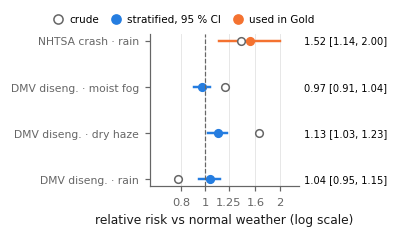

In [8]:
pl = ev[(ev["condition_code"] != "normal") & (ev["events"] >= 30)].copy()
pl["label"] = pl["event_source"].map({"nhtsa_crash": "NHTSA crash", "dmv_disengagement": "DMV diseng."}) \
    + " · " + pl["condition_code"].map({"rain": "rain", "fog_moist": "moist fog", "haze_dry": "dry haze"})
pl = pl.sort_values(["event_source", "condition_code"], ascending=[False, True]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(1.75, 1.8))
y = np.arange(len(pl))[::-1]
for yi, (_, r) in zip(y, pl.iterrows()):
    used = r["used_in_index"] == 1
    col = ORANGE if used else BLUE
    ax.plot([r["ci_low"], r["ci_high"]], [yi, yi], color=col, lw=1.6)
    ax.plot(r["rr_adjusted"], yi, "o", color=col, ms=5)
    ax.plot(r["rr_crude"], yi, "o", mfc="white", mec=rm.INK2, ms=5)
    ax.text(1.03, yi, f"{r['rr_adjusted']:.2f} [{r['ci_low']:.2f}, {r['ci_high']:.2f}]", va="center", fontsize=6.5,
            transform=ax.get_yaxis_transform())
ax.axvline(1, color=rm.INK2, lw=0.8, ls="--")
ax.set_xscale("log")
ax.set_xlim(0.6, 2.4)
ax.set_xticks([0.8, 1, 1.25, 1.6, 2.0])
ax.set_xticklabels(["0.8", "1", "1.25", "1.6", "2"])
ax.minorticks_off()
ax.set_yticks(y)
ax.set_yticklabels(pl["label"], fontsize=7)
ax.set_xlabel("relative risk vs normal weather (log scale)")
style(ax, grid="x")
ax.plot([], [], "o", mfc="white", mec=rm.INK2, label="crude")
ax.plot([], [], "o", color=BLUE, label="stratified, 95 % CI")
ax.plot([], [], "o", color=ORANGE, label="used in Gold")
ax.legend(ncol=3, frameon=False, loc="lower left", bbox_to_anchor=(-0.75, 1.0), handletextpad=0.1, columnspacing=0.6,
          fontsize=6.8)
save(fig, "fig_av_relative_risk_forest")
plt.show()

**Table — cross-check of the stratified ratios with regression models** (`python/04_av_evidence_models.py`: Poisson
GLM with the same strata as fixed effects) and the **hold-out test** (disengagements, last year held out).

In [9]:
glm = pd.read_csv(ROOT / "Data" / "model" / "av_evidence_glm.csv")
same = glm[glm["model"].str.contains("= MH strata|state x month FE", regex=True)]
src_map = {"nhtsa_crash": "nhtsa_crash", "dmv_disengagement": "dmv_disengagement"}
chk = same.merge(ev[["event_source", "condition_code", "rr_adjusted"]],
                 left_on=["data", "condition_code"], right_on=["event_source", "condition_code"])
chk["diff_pct"] = 100 * (chk["rr"] / chk["rr_adjusted"] - 1)
table(chk[["data", "condition_code", "rr_adjusted", "rr", "ci_low", "ci_high", "diff_pct"]]
      .rename(columns={"rr_adjusted": "rr_mantel_haenszel", "rr": "rr_glm", "ci_low": "glm_ci_low", "ci_high": "glm_ci_high"}),
      "table_mh_vs_glm", 3)

saved docs/paper/tables/table_mh_vs_glm.csv


,data,condition_code,rr_mantel_haenszel,rr_glm,glm_ci_low,glm_ci_high,diff_pct
0,nhtsa_crash,rain,1.515,1.482,1.119,1.964,-2.154
1,nhtsa_crash,obscured_unspecified,0.024,0.024,0.006,0.098,2.163
2,dmv_disengagement,rain,1.044,1.095,1.060,1.131,4.912
3,dmv_disengagement,fog_moist,0.973,0.980,0.957,1.003,0.697
4,dmv_disengagement,haze_dry,1.126,1.092,1.060,1.124,-3.043


In [10]:
ho = pd.read_csv(ROOT / "Data" / "model" / "av_evidence_holdout.csv")
table(ho, "table_av_holdout", 3)

saved docs/paper/tables/table_av_holdout.csv


,model,train_days,test_days,nb_alpha,test_deviance,test_mae
0,month-of-year + weekday,1064,366,0.906,1536.524,63.490
1,month-of-year + weekday + day_type,1064,366,0.884,1689.437,63.958


## 4. Readiness score per region and season

In [11]:
rs, reg = rm.pillars(g)
rsc = rm.score(rs)
cl, info = rm.clustering(rsc)
rsc = rsc.merge(cl[["region_code", "season", "cluster_name"]], on=["region_code", "season"])
rank = rm.region_rank(rsc)
tier = rm.ntile3(rank.index.tolist())
agg = rsc.groupby("region_code").agg(readiness=("readiness", "mean"), environment=("contrib_E", "mean"),
                                     safety=("contrib_S", "mean"), infrastructure=("contrib_I", "mean")).loc[rank.index]
bw = rsc.sort_values("readiness").groupby("region_code")
agg["worst_season"] = bw.first()["season"]
agg["worst_score"] = bw.first()["readiness"]
agg["best_season"] = bw.last()["season"]
agg["best_score"] = bw.last()["readiness"]
agg["tier"] = agg.index.map(lambda r: {1: "top", 2: "middle", 3: "bottom"}[tier[r]])
agg.insert(0, "region", agg.index.map(names))
agg.insert(0, "rank", range(1, len(agg) + 1))
table(agg.reset_index(), "table_readiness_by_region", 1)

saved docs/paper/tables/table_readiness_by_region.csv


,region_code,rank,region,readiness,environment,safety,infrastructure,worst_season,worst_score,best_season,best_score,tier
0,JOF,1,Al-Jouf,86.0,28.7,30.6,26.7,spring,80.4,summer,88.8,top
1,EAS,2,Eastern Province,72.0,20.4,31.9,19.6,spring,64.2,autumn,81.3,top
2,HAI,3,Hail,70.7,30.2,20.8,19.7,spring,63.7,autumn,73.9,top
3,NBR,4,Northern Borders,68.8,26.7,16.7,25.4,spring,62.5,summer,72.3,top
4,ASR,5,Aseer,63.8,30.7,13.9,19.3,summer,60.7,autumn,66.3,top
5,TAB,6,Tabuk,58.5,30.0,9.7,18.8,spring,53.4,autumn,61.1,middle
6,MAK,7,Makkah,57.1,27.7,15.3,14.1,summer,55.8,autumn,58.7,middle
7,RIY,8,Riyadh,56.4,17.8,25.0,13.6,spring,38.6,autumn,67.6,middle
8,NAJ,9,Najran,54.5,14.4,20.8,19.3,spring,40.1,autumn,71.3,middle
9,QAS,10,Qassim,52.5,23.2,12.5,16.8,spring,35.9,autumn,59.5,bottom


**Figure — readiness (0–100) by region and season.**

saved docs/paper/figures/fig_readiness_heatmap.png


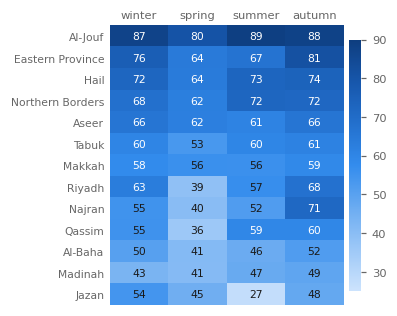

highest: Al-Jouf summer 88.8; lowest: Jazan summer 27.2; spring is the weakest season in 10 of 13 regions


In [12]:
order = rank.index.tolist()
m = rsc.pivot(index="region_code", columns="season", values="readiness").loc[order, rm.SEASONS]
fig, ax = plt.subplots(figsize=(2.95, 3.3))
cmap = LinearSegmentedColormap.from_list("blue", rm.BLUE_RAMP)
lo, hi = np.floor(m.min().min() / 5) * 5, np.ceil(m.max().max() / 5) * 5
im = ax.imshow(m.to_numpy(), cmap=cmap, aspect="auto", vmin=lo, vmax=hi)
for i in range(m.shape[0]):
    for j in range(m.shape[1]):
        v = m.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v > (lo + hi) / 2 else rm.INK)
ax.set_xticks(range(4))
ax.set_xticklabels(rm.SEASONS)
ax.xaxis.tick_top()
ax.set_yticks(range(len(order)))
ax.set_yticklabels([names[r] for r in order], fontsize=7)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.05, pad=0.02)
cb.outline.set_visible(False)
save(fig, "fig_readiness_heatmap")
plt.show()
lowest = rsc.loc[rsc["readiness"].idxmin()]
highest = rsc.loc[rsc["readiness"].idxmax()]
spring_worst = (rsc.loc[rsc.groupby("region_code")["readiness"].idxmin(), "season"] == "spring").sum()
print(f"highest: {names[highest.region_code]} {highest.season} {highest.readiness:.1f}; "
      f"lowest: {names[lowest.region_code]} {lowest.season} {lowest.readiness:.1f}; "
      f"spring is the weakest season in {spring_worst} of 13 regions")

**Figure — what drives each region's score** (mean of its four seasons; each pillar weighs 1/3).

saved docs/paper/figures/fig_readiness_pillars.png


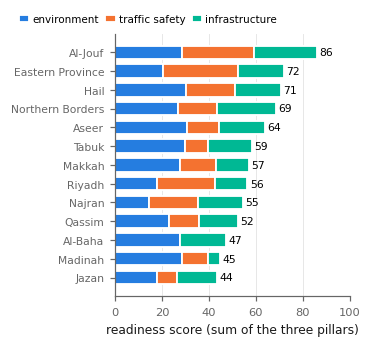

In [13]:
rc = agg.loc[order[::-1], ["environment", "safety", "infrastructure"]]
fig, ax = plt.subplots(figsize=(2.75, 3.1))
left = np.zeros(len(rc))
for col, colr, lab in [("environment", BLUE, "environment"), ("safety", ORANGE, "traffic safety"),
                       ("infrastructure", AQUA, "infrastructure")]:
    ax.barh(range(len(rc)), rc[col], left=left, color=colr, edgecolor="white", linewidth=1.2, height=0.72, label=lab)
    left += rc[col].to_numpy()
for i, v in enumerate(left):
    ax.text(v + 1, i, f"{v:.0f}", va="center", fontsize=7)
ax.set_yticks(range(len(rc)))
ax.set_yticklabels([names[r] for r in rc.index], fontsize=7)
ax.set_xlim(0, 100)
ax.set_xlabel("readiness score (sum of the three pillars)")
ax.legend(ncol=3, frameon=False, loc="lower left", bbox_to_anchor=(-0.45, 1.0), handlelength=1.0, handletextpad=0.3,
          columnspacing=0.6, fontsize=6.8)
style(ax, grid="x")
save(fig, "fig_readiness_pillars")
plt.show()

## 5. Model: KMeans clustering of the 52 region-seasons

In [14]:
sil = pd.DataFrame({"k": list(info["silhouette"].keys()), "silhouette": list(info["silhouette"].values())})
sil["k"] = sil["k"].astype(int)
table(sil, "table_kmeans_silhouette", 3)
print(f"chosen k = {info['k']}; bootstrap ARI mean {info['ari_mean']:.2f} (5-95 %: {info['ari_p05']:.2f}-{info['ari_p95']:.2f}, 200 resamples)")
members = cl.groupby("cluster_name").apply(lambda d: ", ".join(f"{names[r]} {s}" for r, s in zip(d.region_code, d.season)))
summary = cl.groupby("cluster_name").agg(region_seasons=("readiness", "size"), mean_readiness=("readiness", "mean"))
summary["members"] = members
pref = ["High", "Medium-high", "Medium", "Medium-low", "Low"]
summary = summary.loc[[c for c in pref if c in summary.index]]
table(summary.reset_index(), "table_kmeans_clusters", 1)

saved docs/paper/tables/table_kmeans_silhouette.csv
chosen k = 4; bootstrap ARI mean 0.63 (5-95 %: 0.30-0.92, 200 resamples)
saved docs/paper/tables/table_kmeans_clusters.csv


,cluster_name,region_seasons,mean_readiness,members
0,High,11,73.2,"Eastern Province autumn, Eastern Province wint..."
1,Medium-high,7,66.2,"Eastern Province summer, Hail summer, Al-Jouf ..."
2,Medium-low,28,56.4,"Aseer autumn, Aseer spring, Aseer summer, Asee..."
3,Low,6,43.0,"Eastern Province spring, Jazan summer, Najran ..."


**Figure — cluster profiles** (mean standardised feature of each cluster; 0 = average region-season).

saved docs/paper/figures/fig_kmeans_profiles.png


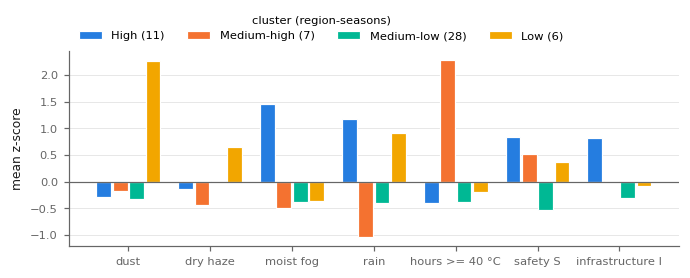

In [15]:
Z = cl[rm.CLUSTER_FEATURES].apply(lambda s: (s - s.mean()) / s.std())
Z["cluster_name"] = cl["cluster_name"]
prof = Z.groupby("cluster_name")[rm.CLUSTER_FEATURES].mean().loc[summary.index]
colors = [BLUE, ORANGE, AQUA, YELLOW, "#ee7fac"]
fig, ax = plt.subplots(figsize=(DOUBLE, 2.3))
x = np.arange(len(rm.CLUSTER_FEATURES))
wdt = 0.8 / len(prof)
for i, (nm, row) in enumerate(prof.iterrows()):
    n = int((cl["cluster_name"] == nm).sum())
    ax.bar(x + i * wdt - 0.4 + wdt / 2, row.to_numpy(), width=wdt - 0.02, color=colors[i], edgecolor="white",
           linewidth=0.8, label=f"{nm} ({n})")
ax.axhline(0, color=rm.INK2, lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(["dust", "dry haze", "moist fog", "rain", "hours >= 40 °C", "safety S", "infrastructure I"])
ax.set_ylabel("mean z-score")
ax.legend(ncol=4, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), title="cluster (region-seasons)",
          title_fontsize=7.5)
style(ax)
save(fig, "fig_kmeans_profiles")
plt.show()

## 6. Model: does weather explain Saudi accidents? (supervised test)

Target: a region's serious-accident rate per 100,000 divided by the national rate of the same year. Samples are
region-years (accidents are annual). Leave-one-region-out is the honest test of generalisation; when a year is left
out, a model can recognise the region from its stable climate, so it is compared with the region-mean baseline.

In [16]:
sup, tests = rm.supervised(g)
sup_t = sup.copy()
sup_t["design"] = sup_t["design"].str.extract(r"^(C\d)")[0]
table(sup_t, "table_supervised_cv", 3)

saved docs/paper/tables/table_supervised_cv.csv


,design,n,cv,model,MAE,R2
0,C1,52,leave one year out,Dummy (mean),0.346,-0.027
1,C1,52,leave one year out,Ridge (alpha by inner CV),0.335,0.059
2,C1,52,leave one year out,"RandomForest (300 trees, depth 3)",0.319,0.159
3,C1,52,leave one year out,"Region mean (identity baseline, no weather)",0.158,0.738
4,C1,52,leave one region out,Dummy (mean),0.362,-0.148
5,C1,52,leave one region out,Ridge (alpha by inner CV),0.421,-0.405
6,C1,52,leave one region out,"RandomForest (300 trees, depth 3)",0.459,-0.744
7,C2,39,leave one year out,Dummy (mean),0.359,-0.010
8,C2,39,leave one year out,Ridge (alpha by inner CV),0.314,0.250
9,C2,39,leave one year out,"RandomForest (300 trees, depth 3)",0.277,0.393


saved docs/paper/figures/fig_supervised_mae.png


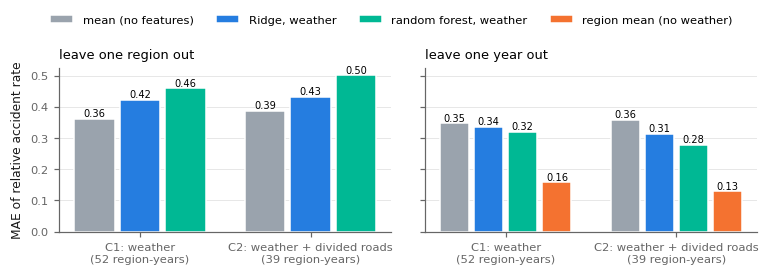

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(DOUBLE, 2.2), sharey=True)
mcol = {"Dummy (mean)": "#9aa3ad", "Ridge (alpha by inner CV)": BLUE, "RandomForest (300 trees, depth 3)": AQUA,
        "Region mean (identity baseline, no weather)": ORANGE}
mlab = {"Dummy (mean)": "mean (no features)", "Ridge (alpha by inner CV)": "Ridge, weather",
        "RandomForest (300 trees, depth 3)": "random forest, weather",
        "Region mean (identity baseline, no weather)": "region mean (no weather)"}
for ax, cv in zip(axes, ["leave one region out", "leave one year out"]):
    d = sup_t[sup_t["cv"] == cv]
    designs = ["C1", "C2"]
    models = [mm for mm in mcol if mm in d["model"].unique()]
    wdt = 0.8 / len(models)
    for i, mm in enumerate(models):
        vals = [d[(d["design"] == ds) & (d["model"] == mm)]["MAE"].iloc[0] for ds in designs]
        xs = np.arange(len(designs)) + i * wdt - 0.4 + wdt / 2
        ax.bar(xs, vals, width=wdt - 0.03, color=mcol[mm], edgecolor="white", label=mlab[mm])
        for xx, v in zip(xs, vals):
            ax.text(xx, v + 0.008, f"{v:.2f}", ha="center", fontsize=6.5)
    ax.set_xticks(range(len(designs)))
    ax.set_xticklabels(["C1: weather\n(52 region-years)", "C2: weather + divided roads\n(39 region-years)"])
    ax.set_title(cv, loc="left")
    style(ax)
axes[0].set_ylabel("MAE of relative accident rate")
h, l = axes[1].get_legend_handles_labels()
fig.legend(h, l, ncol=4, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0))
fig.tight_layout()
save(fig, "fig_supervised_mae")
plt.show()

**Table — rank tests (Spearman) and the good-vs-bad-weather-year comparison (Wilcoxon, query E8).**

In [18]:
rt = pd.DataFrame([(k, v["within_rho"], v["within_p"], v["region_only_rho"], v["region_only_p"], v["cross_rho"], v["cross_p"])
                   for k, v in tests.items() if isinstance(v, dict) and "within_rho" in v],
                  columns=["weather_share", "year_adjusted_rho", "year_adjusted_p", "region_only_rho", "region_only_p",
                           "cross_section_rho", "cross_section_p"])
table(rt, "table_rank_tests", 3)
e8 = pd.DataFrame([(k, v["n_higher"], v["n"], v["stat"], v["p"]) for k, v in tests.items() if k.startswith("wilcoxon")],
                  columns=["test", "regions_higher_in_most_obscured_year", "regions", "wilcoxon_stat", "p"])
table(e8, "table_e8_wilcoxon", 3)
print("most obscured year (year: regions):", tests["most_obscured_years"])

saved docs/paper/tables/table_rank_tests.csv
saved docs/paper/tables/table_e8_wilcoxon.csv
most obscured year (year: regions): {2022: 12, 2023: 1}


## 7. Sensitivity of the readiness ranking

saved docs/paper/figures/fig_sensitivity_tau.png


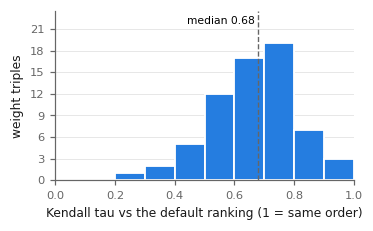

saved docs/paper/tables/table_sensitivity.csv
saved docs/paper/tables/table_tier_stability.csv


,region_code,region,tier_kept_share
0,JOF,Al-Jouf,1.00
2,HAI,Hail,1.00
12,JAZ,Jazan,0.97
6,MAK,Makkah,0.77
3,NBR,Northern Borders,0.77
11,MED,Madinah,0.74
1,EAS,Eastern Province,0.67
4,ASR,Aseer,0.61
10,BAH,Al-Baha,0.56
5,TAB,Tabuk,0.48


In [19]:
sens, sinfo = rm.sensitivity(g, rr, rs)
fig, ax = plt.subplots(figsize=(SINGLE, 2.0))
ax.hist(sens["kendall_tau"], bins=np.linspace(0, 1, 11), color=BLUE, edgecolor="white", linewidth=1.2)
med = sens["kendall_tau"].median()
ax.set_ylim(0, ax.get_ylim()[1] * 1.18)
ax.axvline(med, color=rm.INK2, lw=0.9, ls="--")
ax.text(med - 0.01, ax.get_ylim()[1] * 0.97, f"median {med:.2f}", fontsize=7, va="top", ha="right")
ax.set_xlim(0, 1)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Kendall tau vs the default ranking (1 = same order)")
ax.set_ylabel("weight triples")
style(ax)
save(fig, "fig_sensitivity_tau")
plt.show()
var = [("66 weight triples (step 0.1): median tau", sinfo["tau_median"]),
       ("66 weight triples: minimum tau", sinfo["tau_min"]),
       ("66 weight triples: share with tau >= 0.7", sinfo["share_tau_ge_0.7"]),
       ("conservative environment (dry haze weight 0): tau", sinfo["tau_cons"]),
       (f"rain RR at its CI low {sinfo['rr_rain'][1]:.3f}: tau", sinfo["tau_rr_rain_low"]),
       (f"rain RR at its CI high {sinfo['rr_rain'][2]:.3f}: tau", sinfo["tau_rr_rain_high"])]
if isinstance(sinfo.get("dew_threshold"), dict):
    for t, v in sinfo["dew_threshold"].items():
        var.append((f"fog/haze dew-spread threshold {t} °C (conservative variant): tau", v["tau_vs_default"]))
else:
    print("dew-point threshold test skipped:", sinfo.get("dew_threshold"))
table(pd.DataFrame(var, columns=["variant", "value"]), "table_sensitivity", 3)
kept = pd.Series(sinfo["tier_kept_share"]).rename("tier_kept_share").rename_axis("region_code").reset_index()
kept.insert(1, "region", kept["region_code"].map(names))
table(kept.sort_values("tier_kept_share", ascending=False), "table_tier_stability", 2)

## 8. Consistency check against the pipeline run

The notebook recomputed everything above with the pipeline's own functions. This cell compares the results with the
files that `python/05_readiness_model.py` wrote in the same run. Any mismatch stops the notebook.

In [20]:
M = ROOT / "Data" / "model"
checks = []
p_rsc = pd.read_csv(M / "readiness_region_season.csv").sort_values(["region_code", "season"]).reset_index(drop=True)
n_rsc = rsc.sort_values(["region_code", "season"]).reset_index(drop=True)
checks.append(("readiness per region-season (52)", np.allclose(p_rsc["readiness"], n_rsc["readiness"], atol=1e-9)
               and (p_rsc["cluster_name"] == n_rsc["cluster_name"]).all()))
p_reg = pd.read_csv(M / "readiness_region.csv")
checks.append(("region ranking and scores (13)", list(p_reg["region_code"]) == list(agg.index)
               and np.allclose(p_reg["readiness"], agg["readiness"], atol=1e-9)))
p_sup = pd.read_csv(M / "supervised_weather_accidents.csv")
d_sup = np.abs(p_sup[["MAE", "R2"]].to_numpy() - sup[["MAE", "R2"]].to_numpy())
is_rf = sup["model"].str.startswith("RandomForest").to_numpy()
sup_exact = d_sup.max() < 1e-9
# a random forest can differ in the 4th decimal between operating systems (floating point in split thresholds);
# on the machine that ran the pipeline the match is exact
sup_xplat = d_sup[~is_rf].max() < 1e-9 and d_sup[is_rf].max() < 5e-3
checks.append(("supervised CV results" + ("" if sup_exact else
               f" (random forest differs by {d_sup[is_rf].max():.4f}: run on another operating system)"),
               sup_exact or sup_xplat))
p_sens = pd.read_csv(M / "sensitivity_weights.csv")
checks.append(("sensitivity, 66 weight triples", np.allclose(p_sens["kendall_tau"], sens["kendall_tau"], atol=1e-9)))
summ = json.loads((M / "model_summary.json").read_text())
checks.append(("clustering k, silhouette, ARI", summ["clustering"]["k"] == info["k"]
               and abs(summ["clustering"]["ari_mean"] - info["ari_mean"]) < 1e-9))
for name, ok in checks:
    print(("PASS " if ok else "FAIL ") + name)
assert all(ok for _, ok in checks), "the notebook does not reproduce the pipeline run"
print("\nThe notebook reproduces the pipeline run." + ("" if sup_exact else " (Exact on the machine that ran the pipeline.)"))

PASS readiness per region-season (52)
PASS region ranking and scores (13)
PASS supervised CV results (random forest differs by 0.0015: run on another operating system)
PASS sensitivity, 66 weight triples
PASS clustering k, silhouette, ARI

The notebook reproduces the pipeline run. (Exact on the machine that ran the pipeline.)
